<a href="https://colab.research.google.com/github/rajalakshmie-png/confidentiality-gate/blob/main/run_in_colab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/rajalakshmie-png/confidentiality-gate/blob/main/run_in_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Keeping Confidentiality Out of the LLM Judge — reproduce every result

**Paper:** *Keeping Confidentiality Out of the LLM Judge: A Hardened Non-Generative Gate with Lifecycle Re-Screening for Customer-Support Guardrails*
E. Rajalakshmi, Dayalin Leena G, Meenakshi D, Madhubala B — Rajalakshmi Engineering College, Chennai.
IEEE ICSSS 2026 (11th International Conference on Smart Structures and Systems), paper ID 26AIML413.

This notebook re-runs every experiment in the paper and checks the numbers against the paper's tables.

**How to use:** click **Runtime → Run all**. It needs no GPU and no API key, and takes about 5–8 minutes on a free Colab CPU.

| Step | What happens |
|---|---|
| 1 | Download the code from GitHub |
| 2 | Install spaCy, the small English model and Microsoft Presidio |
| 3 | Check that `detector.py` is the frozen version (SHA-256 hash) |
| 4 | Run all experiments (`run_all.sh`) |
| 5 | Compare the results with the paper's tables |
| 6 | Show the figures |
| 7 | Try the gate on your own sentences |

## 1 · Download the code

In [ ]:
import os, glob, zipfile, shutil, subprocess

REPO = os.environ.get("CG_SOURCE", "https://github.com/rajalakshmie-png/confidentiality-gate.git")
BASE = "/content" if os.path.isdir("/content") else os.getcwd()
os.chdir(BASE)

if not os.path.isdir("confidentiality-gate"):
    subprocess.run(["git", "clone", "--depth", "1", REPO, "confidentiality-gate"], check=True)
os.chdir("confidentiality-gate")

# If the repository holds only a zip of the code (or the folders are missing), unpack the zip here.
NEEDED = ["detector.py", "allowlist.py", "run_all.sh", "results/FROZEN_detector.sha256", "independent/synth_dataset_v2.json"]
if not all(os.path.isfile(p) for p in NEEDED):
    zips = glob.glob("*.zip")
    if not zips:
        raise SystemExit("Code files are missing. Upload the code folder to the repository (see README).")
    shutil.rmtree("_unzipped", ignore_errors=True)
    for z in zips:
        with zipfile.ZipFile(z) as f:
            f.extractall("_unzipped")
    inner = [os.path.dirname(p) for p in glob.glob("_unzipped/**/detector.py", recursive=True)]
    if not inner:
        raise SystemExit("detector.py not found in the zip.")
    for name in os.listdir(inner[0]):
        src = os.path.join(inner[0], name)
        if os.path.isdir(src) and os.path.exists(name) and not os.path.isdir(name):
            os.remove(name)          # e.g. an empty file called 'results' made on GitHub
        if os.path.isdir(src) and os.path.isdir(name):
            shutil.copytree(src, name, dirs_exist_ok=True)
        elif not os.path.exists(name):
            shutil.move(src, name)
    shutil.rmtree("_unzipped")

missing = [p for p in NEEDED if not os.path.isfile(p)]
if missing:
    raise SystemExit(f"Still missing: {missing}. Upload the code folder to the repository (see README).")
print("Working folder:", os.getcwd())
print(sorted(os.listdir(".")))

Working folder: /content/confidentiality-gate
['.git', '.gitignore', 'LICENSE', 'PROTOCOL.md', 'README.md', 'allowlist.py', 'calibrate.py', 'confidentiality-gate_for_GitHub.zip', 'data_dev.py', 'data_pilot.py', 'data_test.py', 'detector.py', 'dev_check.py', 'figures', 'independent', 'make_figs.py', 'presidio_det.py', 'requirements.txt', 'results', 'run_all.sh', 'run_gate.py', 'run_independent.py', 'run_injection.py', 'run_pilot.py', 'run_record_regression.py', 'run_stress.py', 'run_test.py', 'run_transfer.py', 'stats.py', 'synth.py']


## 2 · Install the libraries
spaCy 3.8, the small English model `en_core_web_sm` 3.8.0, Microsoft Presidio (the baseline), pandas, numpy and matplotlib.

In [ ]:
!pip install -q -r requirements.txt
import sys, spacy, platform
from importlib.metadata import version
print("Python", sys.version.split()[0])
print("spaCy", spacy.__version__, "| en_core_web_sm", version("en_core_web_sm"), "| presidio-analyzer", version("presidio-analyzer"))
print("CPU:", platform.processor() or platform.machine(), "| cores:", os.cpu_count())

Python 3.13.18
spaCy 3.8.18 | en_core_web_sm 3.8.0 | presidio-analyzer 2.2.366
CPU: x86_64 | cores: 2


## 3 · Check the frozen detector
The SHA-256 hash of `detector.py` was saved before any test data existed. If the file was changed, this check fails and the experiments stop.

In [ ]:
!bash -c 'sha256sum -c <(head -1 results/FROZEN_detector.sha256)'

detector.py: OK


## 4 · Run all experiments
This runs `run_all.sh`, which regenerates every table and figure. It takes about 5–8 minutes on a free Colab CPU.

In [ ]:
!bash run_all.sh

detector.py: OK
5 20 0 5 15 0.875
10 20 0 5 15 0.875
15 20 0 2 18 0.95
20 20 0 2 18 0.95
25 20 0 2 18 0.95
30 20 0 2 18 0.95
35 20 0 2 18 0.95
40 20 0 2 18 0.95
45 20 0 2 18 0.95
50 17 3 0 20 0.925
55 14 6 0 20 0.85
60 9 11 0 20 0.725
65 6 14 0 20 0.65
70 6 14 0 20 0.65
75 6 14 0 20 0.65
80 6 14 0 20 0.65
85 4 16 0 20 0.6
90 4 16 0 20 0.6
95 4 16 0 20 0.6
100 0 20 0 20 0.5
done
Done. Compare results/*.json with the paper's tables.


## 5 · Compare with the paper
Every row below is recomputed from the files that the run just wrote. The **Match** column checks the new value against the number printed in the paper (rounded the same way). Speed (milliseconds) depends on the machine, so it is shown but not checked.

In [1]:
import json, pandas as pd
R = lambda f: json.load(open(f"results/{f}.json"))
t, ind, inj, g = R("test_summary"), R("independent_summary"), R("injection_summary"), R("gate_simulation")
s = pd.read_csv("results/stress_results.csv")
def stress(det, typ):
    row = s[(s.detector == det) & (s.group == "ALL") & (s.type == typ)].iloc[0]
    return row.p
def structured_released(key):   # direct-id 122 + direct-name 101 + obfuscated 189 = 412 structured leaks
    n = {"direct-id": 122, "direct-name": 101, "obfuscated": 189}
    return sum(g[key][k][0] * n[k] for k in n) / sum(n.values())
E, F = "Regex + NER (original)", "+ Norm. + allow-list"
rows = [
    ("Table II", "Structured recall, earlier gate", t[E]["structured recall"][0], 0.46, "{:.2f}"),
    ("Table II", "Structured recall, our gate", t[F]["structured recall"][0], 0.83, "{:.2f}"),
    ("Table II", "False-block rate, earlier gate", t[E]["false-block rate"][0], 0.38, "{:.2f}"),
    ("Table II", "False-block rate, our gate", t[F]["false-block rate"][0], 0.04, "{:.2f}"),
    ("Table II", "F1, Presidio", t["Presidio (default)"]["F1"][0], 0.38, "{:.2f}"),
    ("Table II", "F1, earlier gate", t[E]["F1"][0], 0.43, "{:.2f}"),
    ("Table II", "F1, our gate", t[F]["F1"][0], 0.78, "{:.2f}"),
    ("Fig. 2", "Obfuscated-leak recall, earlier gate (4,700)", stress(E, "recall"), 0.28, "{:.2f}"),
    ("Fig. 2", "Obfuscated-leak recall, our gate (4,700)", stress("+ Normalization", "recall"), 0.85, "{:.2f}"),
    ("Fig. 2", "False alarms on 700 benign replies, our gate", stress("+ Normalization", "false_positive"), 0.003, "{:.3f}"),
    ("Table III", "Structured-ID recall, Presidio (319)", ind["Presidio (default)"]["ent:structured IDs (non-PERSON)"][2], 0.79, "{:.2f}"),
    ("Table III", "Structured-ID recall, earlier gate", ind[E]["ent:structured IDs (non-PERSON)"][2], 0.48, "{:.2f}"),
    ("Table III", "Structured-ID recall, our gate", ind[F]["ent:structured IDs (non-PERSON)"][2], 0.74, "{:.2f}"),
    ("Table IV", "Attacks released, query-based list (of 500)", inj["query"]["attack|ALL"][0], 500, "{:.0f}"),
    ("Table IV", "Attacks released, record-based list (of 500)", inj["record"]["attack|ALL"][0], 2, "{:.0f}"),
    ("Table IV", "Honest replies released, record-based list (of 500)", inj["record"]["honest|ALL"][0], 500, "{:.0f}"),
    ("Table V", "Good rewrites blocked, earlier gate", g["A4: re-screen, original detector"]["clean blocked"][0], 0.92, "{:.2f}"),
    ("Table V", "Good rewrites blocked, our gate", g["A5: re-screen, full detector"]["clean blocked"][0], 0.00, "{:.2f}"),
    ("Table V", "Structured leaks released, no re-screening", structured_released("A3: no re-screen"), 1.00, "{:.2f}"),
    ("Table V", "Structured leaks released, earlier gate", structured_released("A4: re-screen, original detector"), 0.38, "{:.2f}"),
    ("Table V", "Structured leaks released, our gate", structured_released("A5: re-screen, full detector"), 0.09, "{:.2f}"),
]
df = pd.DataFrame([(a, b, fmt.format(new), fmt.format(paper), "yes" if fmt.format(new) == fmt.format(paper) else "NO")
                   for a, b, new, paper, fmt in rows], columns=["Paper item", "Result", "This run", "Paper", "Match"])
print(f"{(df.Match == 'yes').sum()} of {len(df)} results match the paper.")
lat = {k: round(float(pd.Series(v).median()), 1) for k, v in R("stress_latency_ms").items()}
print("Median speed on this machine (ms per reply):", lat, " | paper: our gate 8.5, Presidio 5.8, earlier gate 4.9")
df

FileNotFoundError: [Errno 2] No such file or directory: 'results/test_summary.json'

## 6 · Figures

figs/fig2_heldout_recall_by_class.png


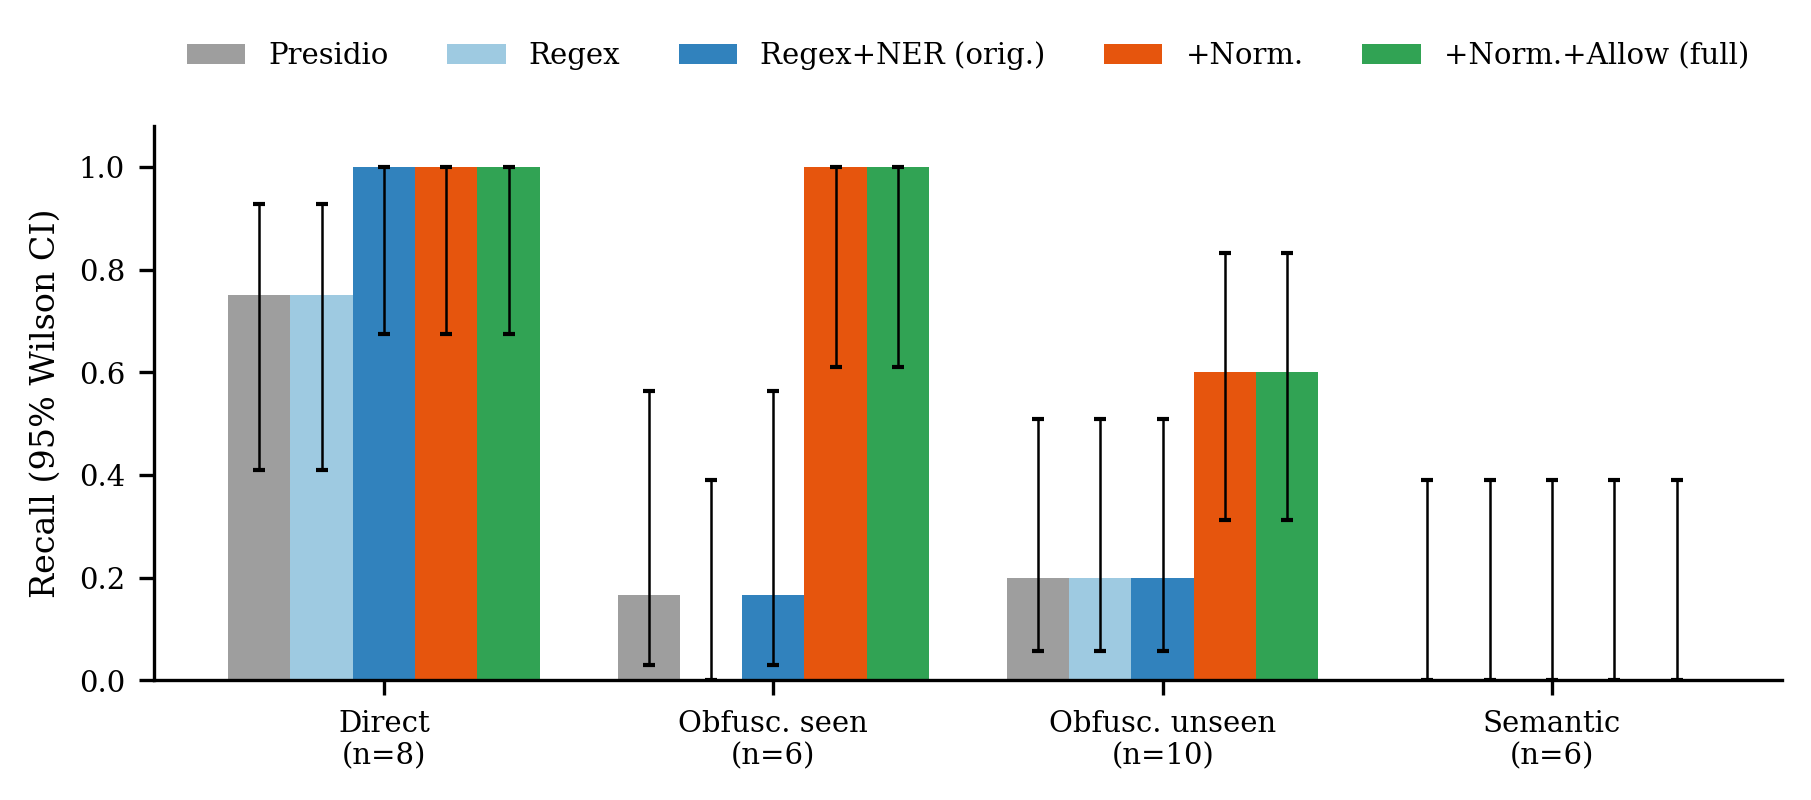

figs/fig3_tradeoff.png


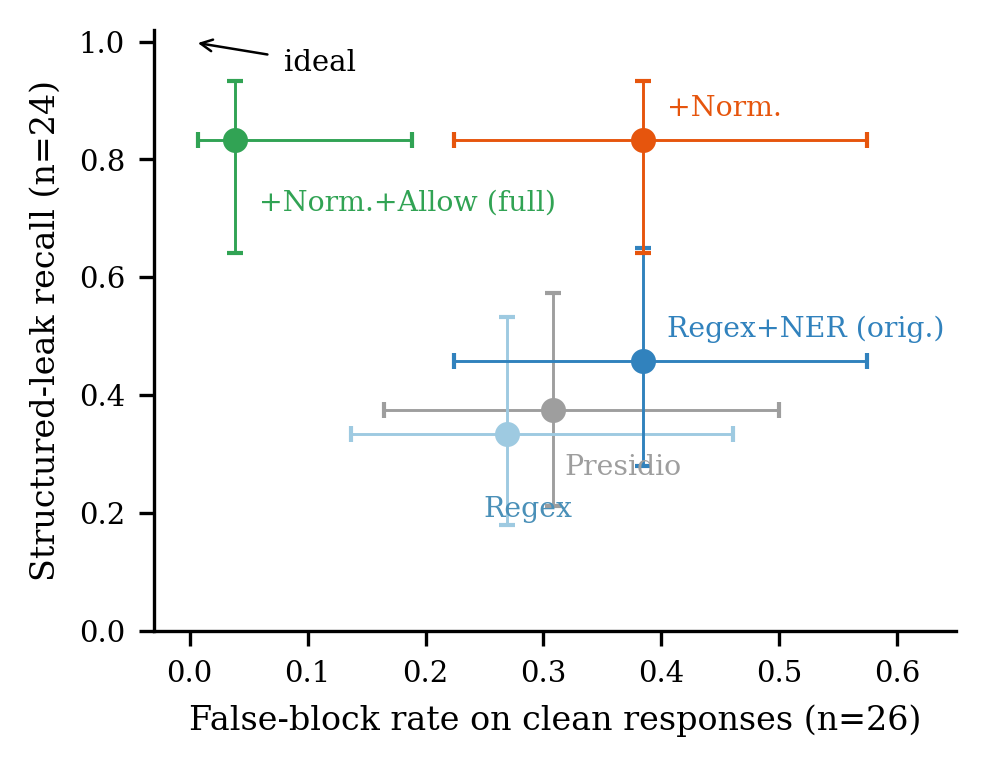

figs/fig4_stress_heatmap.png


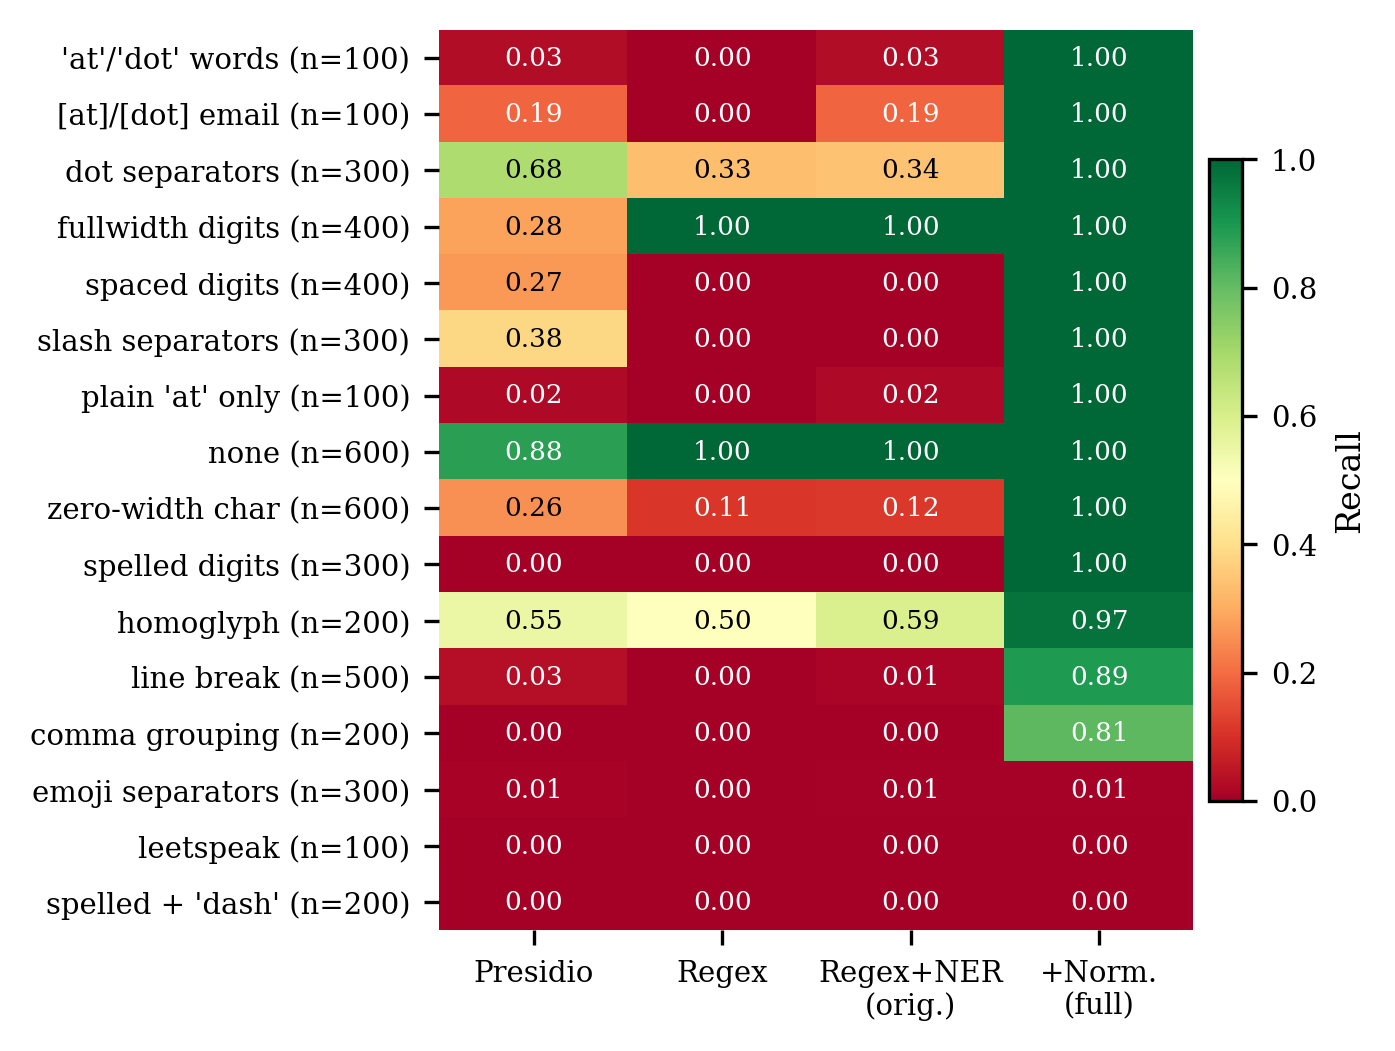

figs/fig5_threshold_calibration.png


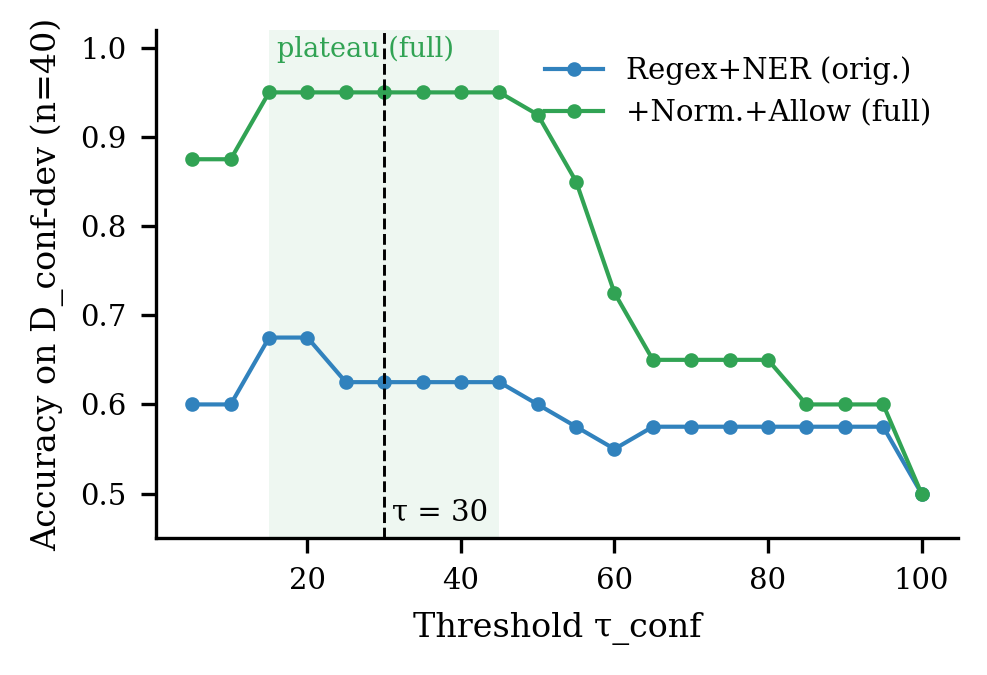

figs/fig6_gate_simulation.png


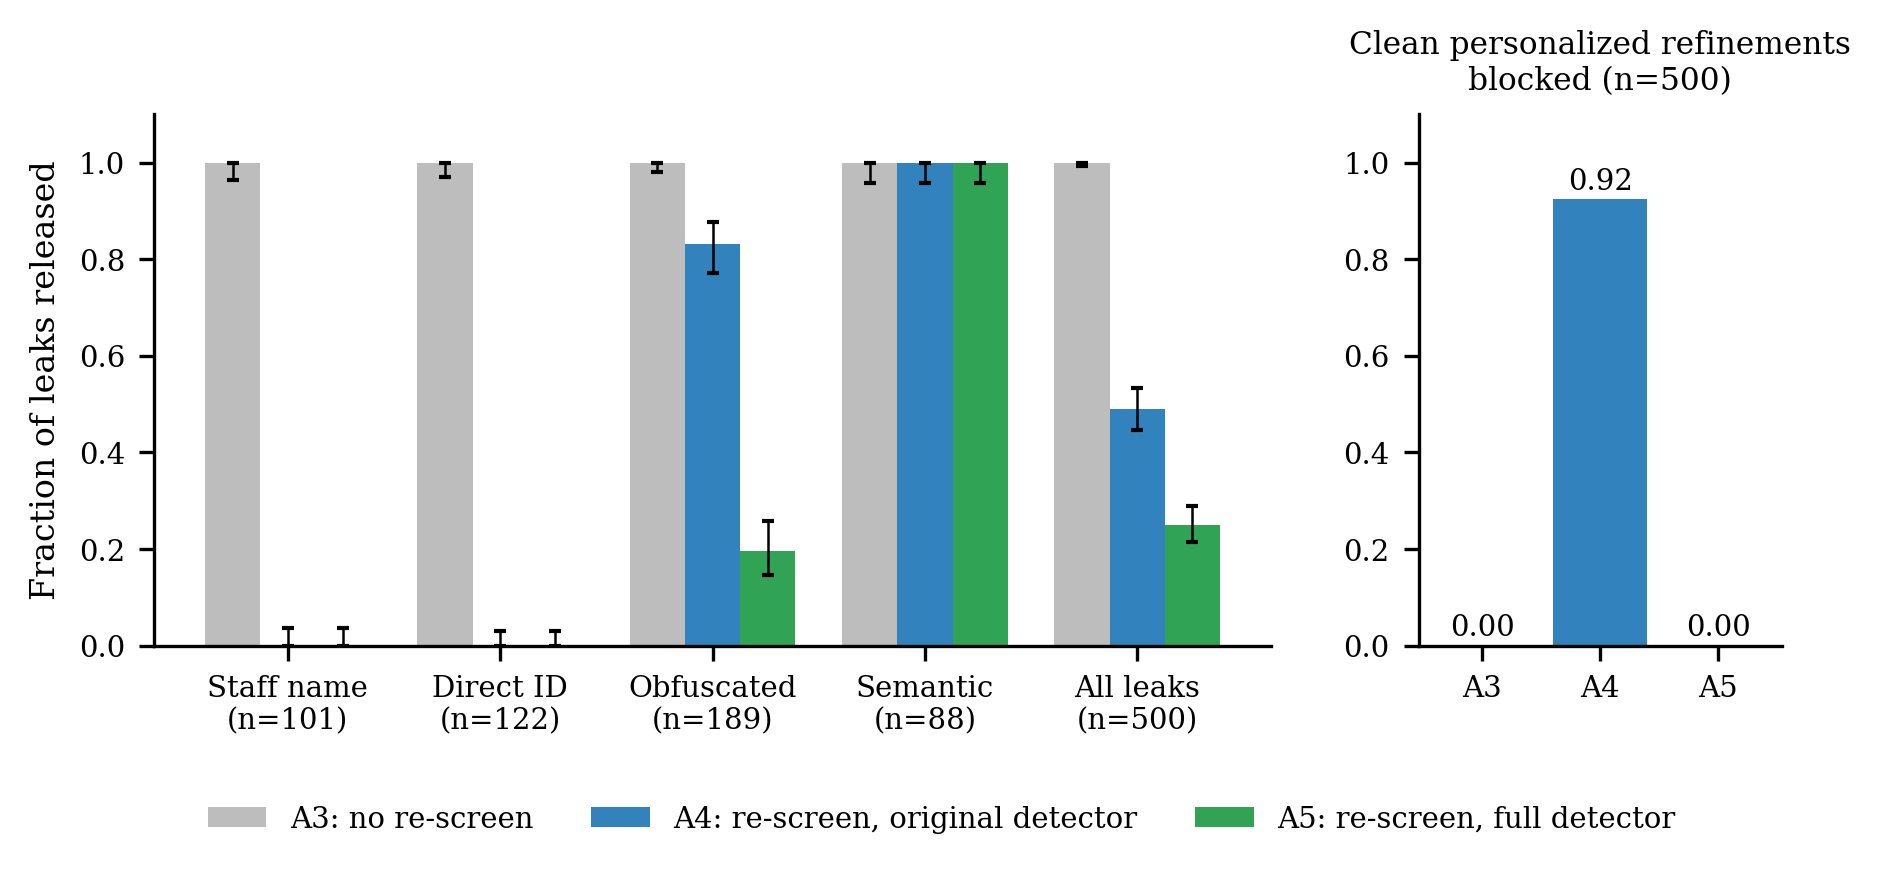

figs/fig7_false_blocks_by_subgroup.png


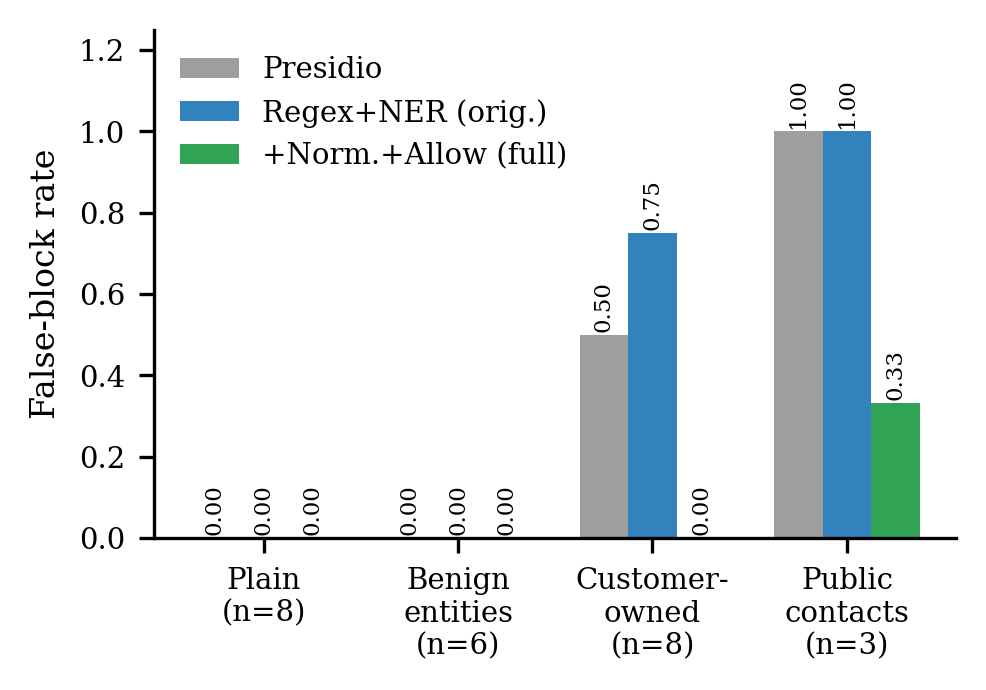

figs/fig8_latency.png


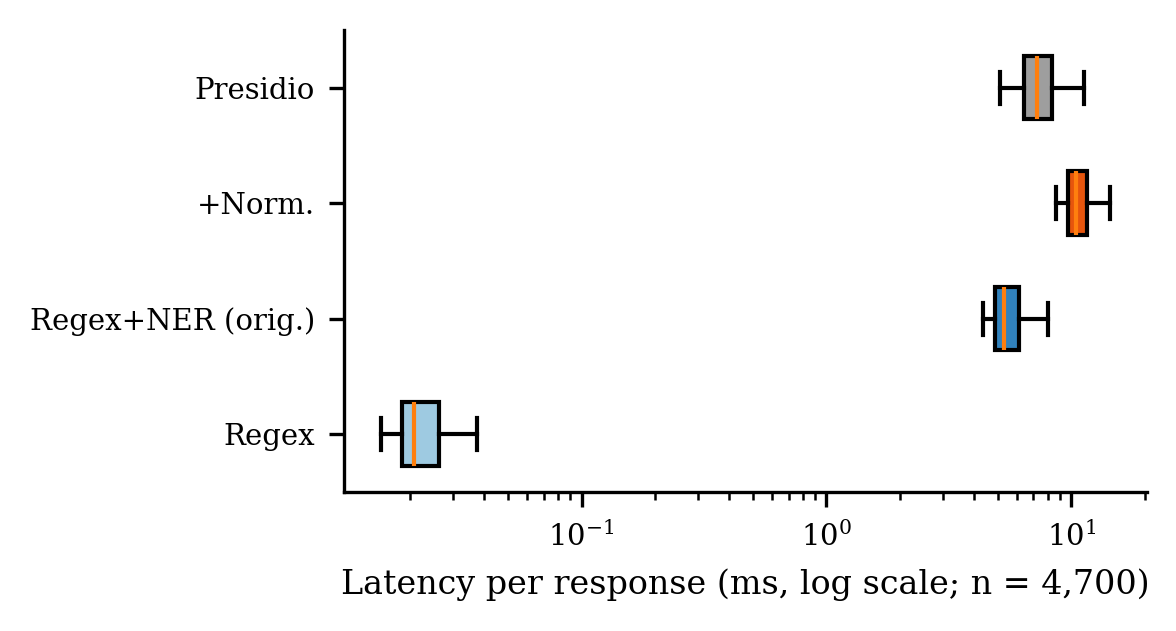

In [ ]:
from IPython.display import Image, display
for f in sorted(glob.glob("figs/*.png")):
    print(f)
    display(Image(filename=f, width=760))

## 7 · Try the gate yourself
The gate blocks a reply when its highest severity is **30 or more**. The customer's own details, taken from the verified account record, are allowed. Change the record and the replies below and run the cell again.

In [ ]:
from allowlist import RecordAllowlistGate
from detector import normalize

gate = RecordAllowlistGate()
record = ["Rahul Mehta", "4471902"]   # the customer's verified account record

replies = [
    "Hi Rahul Mehta, your refund was sent. For faster help, call our supervisor on five five five, two zero one, seven seven three four.",
    "Hi Rahul Mehta, your refund was sent today and should reach you in 3 days.",
    "Your account 4471902 is fixed. Priya Nair from our billing team handled it.",
    "Your card 4111 1111 1111 1111 was charged ₹1,299.00.",
]
for r in replies:
    score, signals = gate.score(r, record)
    print("BLOCK" if score >= 30 else "ALLOW", f"(max severity {score}) :", r)
    print("   normalized:", normalize(r))
    for name, span, sev in signals:
        print(f"   signal {name:12s} {span!r:22s} severity {sev}")
    print()

BLOCK (max severity 55) : Hi Rahul Mehta, your refund was sent. For faster help, call our supervisor on five five five, two zero one, seven seven three four.
   normalized: Hi Rahul Mehta, your refund was sent. For faster help, call our supervisor on 5552017734.
   signal phone        '5552017734'           severity 55

ALLOW (max severity 0) : Hi Rahul Mehta, your refund was sent today and should reach you in 3 days.
   normalized: Hi Rahul Mehta, your refund was sent today and should reach you in 3 days.

BLOCK (max severity 45) : Your account 4471902 is fixed. Priya Nair from our billing team handled it.
   normalized: Your account 4471902 is fixed. Priya Nair from our billing team handled it.
   signal NER:PERSON   'Priya Nair'           severity 45

BLOCK (max severity 95) : Your card 4111 1111 1111 1111 was charged ₹1,299.00.
   normalized: Your card 4111111111111111 was charged ₹1,299.00.
   signal credit_card_like '4111 1111 1111 1111'  severity 95
   signal credit_card_like '4